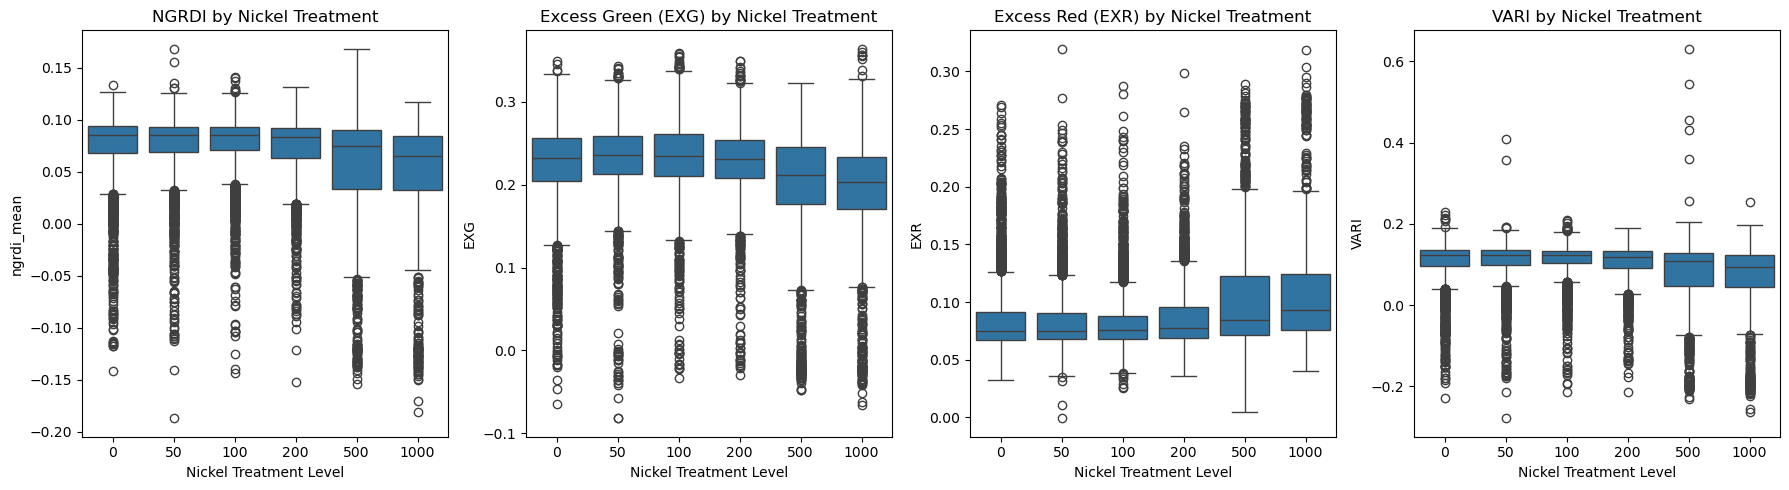

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the datasets
design_df = pd.read_csv("design.csv")
features_df = pd.read_csv("features.csv")

# 2. Merge the datasets on shared unique identifiers
merged_df = pd.merge(design_df, features_df, on=['sample_key', 'experiment_id', 'plant_id', 'round_id'], how='inner')

# 3. Calculate Vegetation Indices
R = merged_df['proportional_red_mean']
G = merged_df['proportional_green_mean']
B = merged_df['proportional_blue_mean']

merged_df['EXG'] = 2 * G - R - B
merged_df['EXR'] = 1.4 * R - G

# Add a small epsilon (1e-6) to VARI denominator to prevent division by zero errors
merged_df['VARI'] = (G - R) / (G + R - B + 1e-6) 

# 4. Calculate Survival (20,000 pixel max area threshold)
# Group by plant_id to find the maximum area reached across all imaging rounds
max_area_per_plant = merged_df.groupby('plant_id')['area_px'].max().reset_index()
max_area_per_plant['survived'] = (max_area_per_plant['area_px'] > 20000).astype(int)
max_area_per_plant = max_area_per_plant.rename(columns={'area_px': 'max_area_px'})

# Merge the binary survival outcome back into the main dataset
merged_df = pd.merge(merged_df, max_area_per_plant[['plant_id', 'survived', 'max_area_px']], on='plant_id', how='left')

# 5. Visualize NGRDI, EXG, and EXR across Nickel Treatments
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

sns.boxplot(data=merged_df, x='treatment', y='ngrdi_mean', ax=axes[0])
axes[0].set_title('NGRDI by Nickel Treatment')
axes[0].set_xlabel('Nickel Treatment Level')

sns.boxplot(data=merged_df, x='treatment', y='EXG', ax=axes[1])
axes[1].set_title('Excess Green (EXG) by Nickel Treatment')
axes[1].set_xlabel('Nickel Treatment Level')

sns.boxplot(data=merged_df, x='treatment', y='EXR', ax=axes[2])
axes[2].set_title('Excess Red (EXR) by Nickel Treatment')
axes[2].set_xlabel('Nickel Treatment Level')

sns.boxplot(data=merged_df, x='treatment', y='VARI', ax=axes[3])
axes[3].set_title('VARI by Nickel Treatment')
axes[3].set_xlabel('Nickel Treatment Level')

plt.tight_layout()
plt.show()

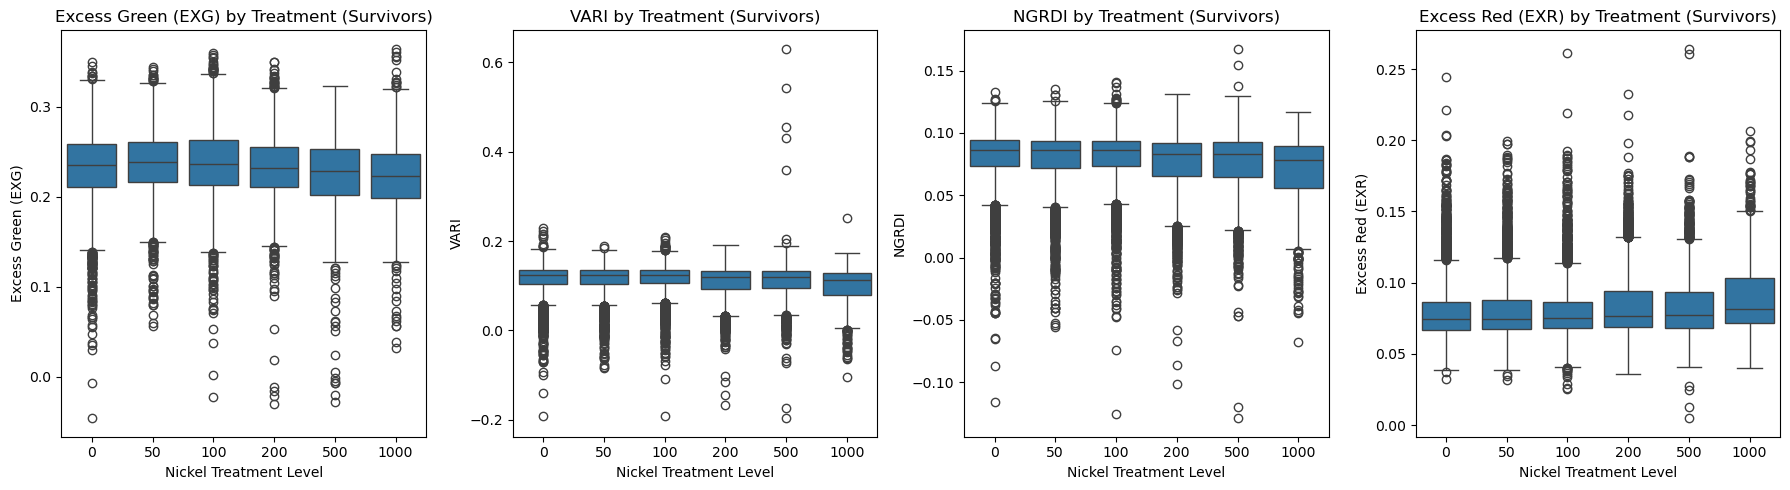

In [19]:
# 5. Isolate Survivors Only
survivors_df = merged_df[merged_df['survived'] == 1].copy()

# 6. Generate the Visualizations
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Plot Excess Green (EXG)
sns.boxplot(data=survivors_df, x='treatment', y='EXG', ax=axes[0])
axes[0].set_title('Excess Green (EXG) by Treatment (Survivors)')
axes[0].set_xlabel('Nickel Treatment Level')
axes[0].set_ylabel('Excess Green (EXG)')

# Plot VARI
sns.boxplot(data=survivors_df, x='treatment', y='VARI', ax=axes[1])
axes[1].set_title('VARI by Treatment (Survivors)')
axes[1].set_xlabel('Nickel Treatment Level')
axes[1].set_ylabel('VARI')

# Plot NGRDI
sns.boxplot(data=survivors_df, x='treatment', y='ngrdi_mean', ax=axes[2])
axes[2].set_title('NGRDI by Treatment (Survivors)')
axes[2].set_xlabel('Nickel Treatment Level')
axes[2].set_ylabel('NGRDI')

sns.boxplot(data=survivors_df, x='treatment', y='EXR', ax=axes[3])
axes[3].set_title('Excess Red (EXR) by Treatment (Survivors)')
axes[3].set_xlabel('Nickel Treatment Level')
axes[3].set_ylabel('Excess Red (EXR)')

plt.tight_layout()
plt.show()

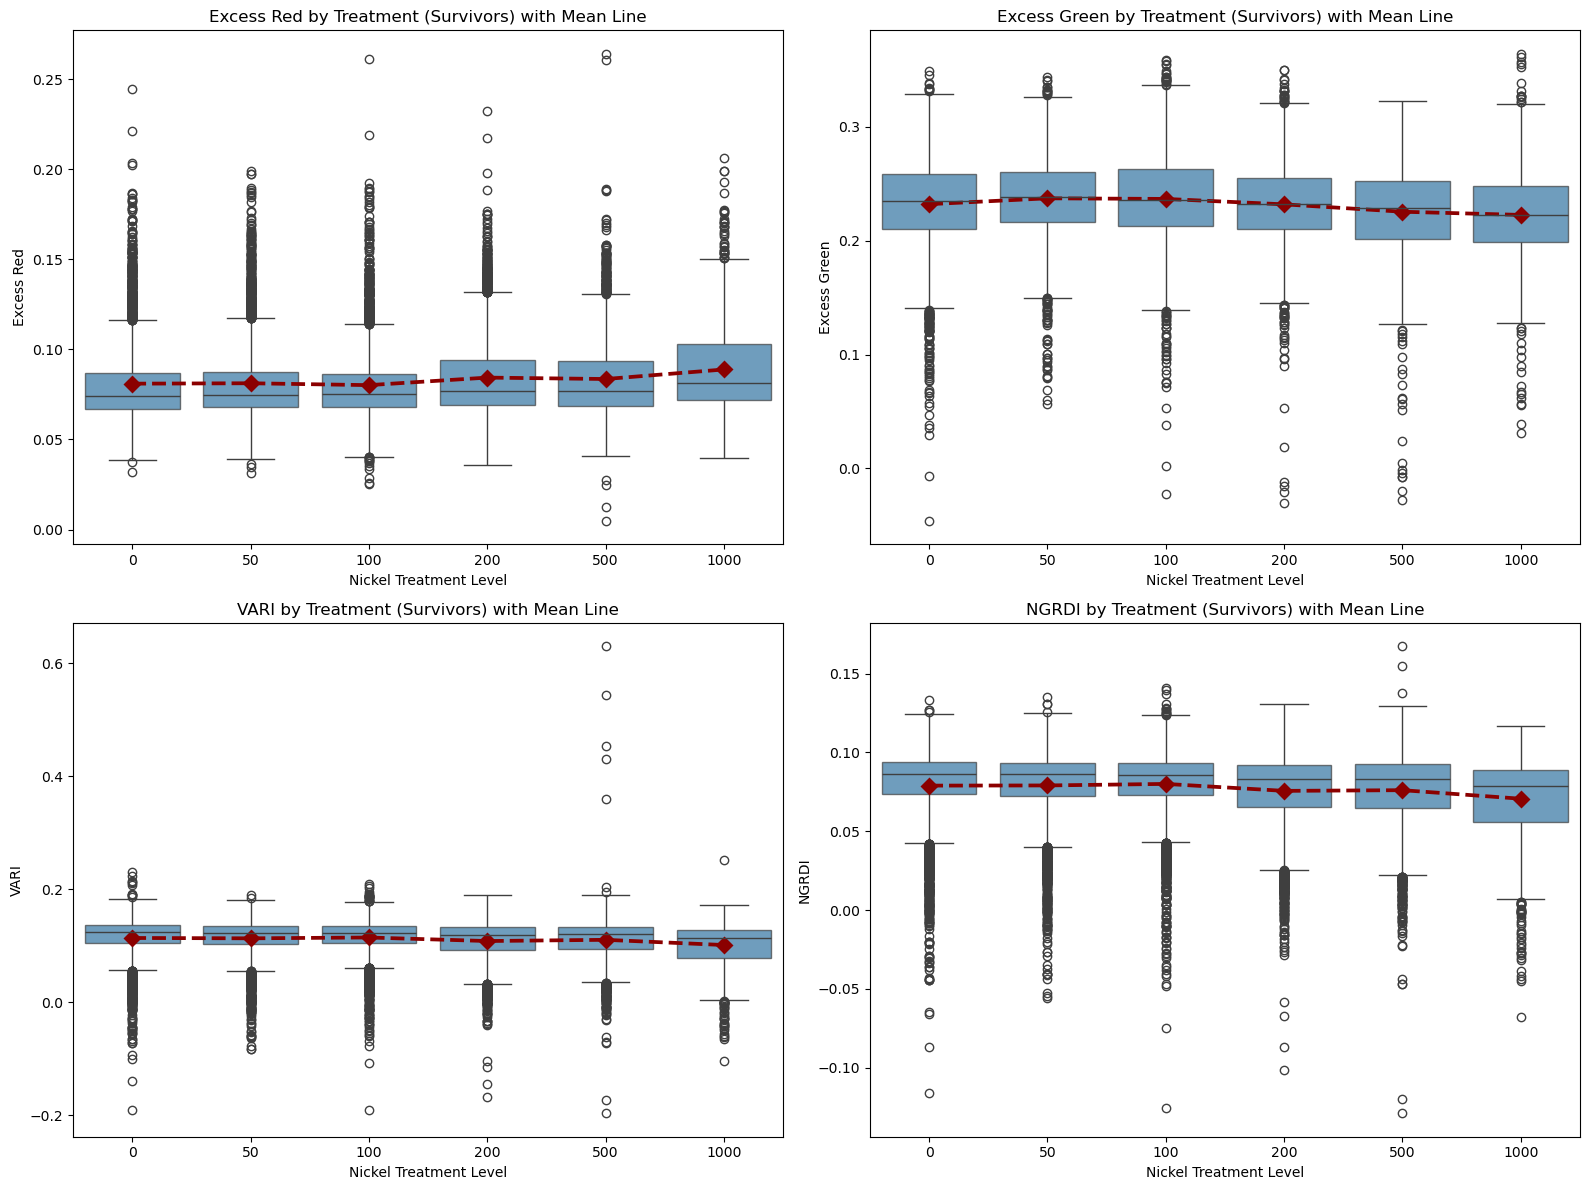

In [29]:
# 4. Generate the Visualizations with Mean Lines Overlay
metrics = {'EXR': 'Excess Red', 'EXG': 'Excess Green', 'VARI': 'VARI', 'ngrdi_mean': 'NGRDI'}
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, (metric, title) in enumerate(metrics.items()):
    # Create the standard boxplot, adding transparency (alpha) to make the line pop
    sns.boxplot(data=survivors_df, x='treatment', y=metric, ax=axes[i], boxprops={'alpha': 0.7})
    
    # Overlay the mean line connecting the treatments
    sns.pointplot(data=survivors_df, x='treatment', y=metric, ax=axes[i], 
                  color='darkred', linestyles='--', markers='D', errorbar=None)
    
    axes[i].set_title(f'{title} by Treatment (Survivors) with Mean Line')
    axes[i].set_xlabel('Nickel Treatment Level')
    axes[i].set_ylabel(title)

plt.tight_layout()
plt.show()